Try to figure out whats going on!

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro
numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx
# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt
#plt.style.use("ICIWstyle")

In [2]:
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    run_inference,
    validate_against_holdout,
    sample_prior,
    calculate_partial_pressures,
    predict,
    generate_synthetic_data,
    sample_posterior,
    TRUE_PARAMS,
)

In [3]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")
    return fig, ax

In [4]:
from scipy.stats import qmc
T_range = jnp.array([450, 600])
p_range = jnp.array([3, 9])
c2h_range = jnp.array([0.2, 4])
c2m_range = jnp.array([0.5, 1000])
c2w_range = jnp.array([0.5, 1000])
c2i_range = jnp.array([0.05, 1])

n_obs = 98
sampler = qmc.LatinHypercube(d=6)
sample = sampler.random(n=n_obs)

# Scale samples to the appropriate ranges
T_lhs = qmc.scale(sample[:, 0:1], T_range[0], T_range[1])
p_lhs = qmc.scale(sample[:, 1:2], p_range[0], p_range[1])
c2h_lhs = qmc.scale(sample[:, 2:3], c2h_range[0], c2h_range[1])
c2m_lhs = qmc.scale(sample[:, 3:4], c2m_range[0], c2m_range[1])
c2w_lhs = qmc.scale(sample[:, 4:5], c2w_range[0], c2w_range[1])
c2i_lhs = qmc.scale(sample[:, 5:6], c2i_range[0], c2i_range[1])

proposals = jnp.column_stack([T_lhs, p_lhs, c2h_lhs, c2m_lhs, c2w_lhs, c2i_lhs])
print(proposals.shape)

(98, 6)


In [5]:
Ts = proposals[:, 0].reshape(-1, 1)
ps = proposals[:, 1].reshape(-1, 1)
c2hs = proposals[:, 2].reshape(-1, 1)
c2ms = proposals[:, 3].reshape(-1, 1)
c2ws = proposals[:, 4].reshape(-1, 1)
c2is = proposals[:, 5].reshape(-1, 1)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

display(pi.shape)

(98, 5)

In [6]:
T_obs, pi_obs, r_obs = generate_synthetic_data(Ts, ps, c2hs, c2ms, c2ws, c2is, 0.01)
print(T_obs.shape)
print(r_obs.shape)

(98, 1)
(98, 1)


In [7]:
idata = sample_prior()

Input shape: T.shape=(1, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (1, 1)
plate shape: (1, 1)


In [8]:
display(idata)

Inference data with groups:
	> prior

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'Ea_k'}>]],
      dtype=object)

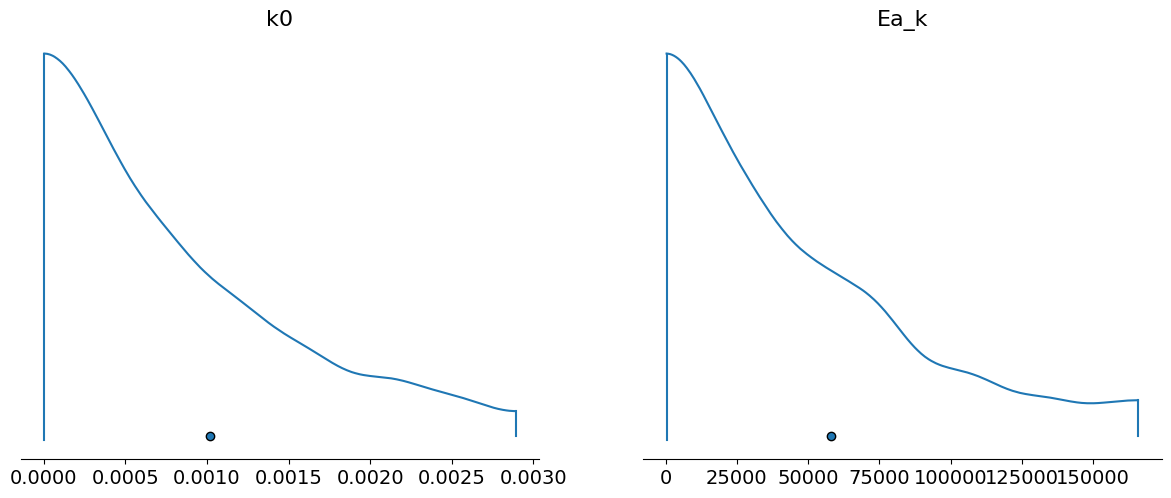

In [9]:
az.plot_density(
    idata,
    group="prior",
    var_names=[
        "k0",
        "Ea_k",
    ]
)

In [10]:
idata.extend(run_inference(
    T=T_obs,
    p_i = pi_obs,
    r_obs = r_obs,
))

Starting MCMC: 4 chains × (1000 warmup + 4000 samples)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
MCMC sampling completed successfully!
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 1)
Prediction shape: (98, 1)
plate shape: (98, 1)


In [11]:
display(idata)

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> prior
	> observed_data

In [12]:
r_post = predict(idata, T_obs, pi_obs, key="posterior")
display(r_post.shape)

(98, 25)

In [13]:
@interact(
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idata,
        key="posterior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Proposal:', max=97), Output()), _dom_classes=('widget-in…

array([[<Axes: >, <Axes: >, <Axes: xlabel='k0'>],
       [<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>]], dtype=object)

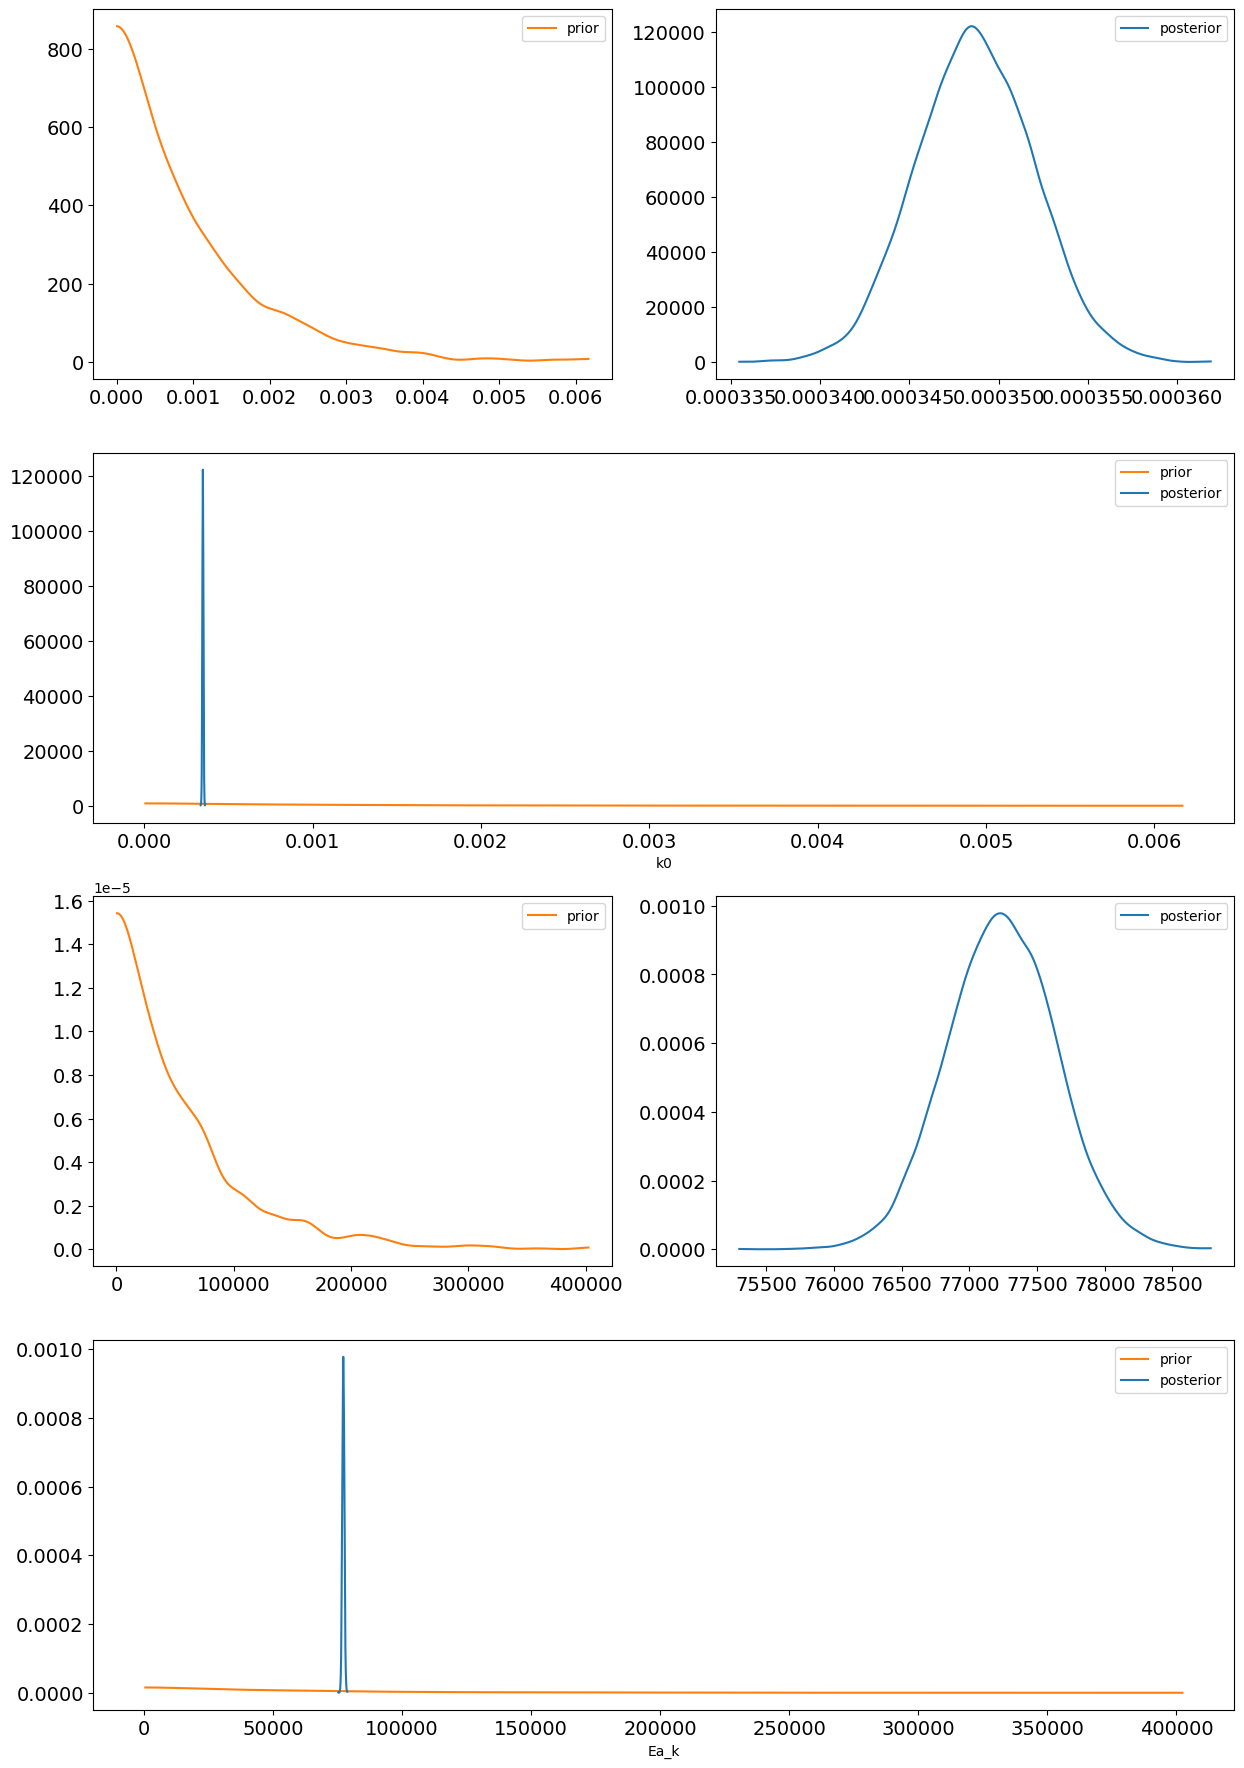

In [14]:
az.plot_dist_comparison(
    idata,
    var_names=[
        "k0",
        "Ea_k",
    ]
)

In [15]:
print(T_obs.shape, pi_obs.shape)

(98, 1) (98, 5)


In [16]:
sample_posterior(idata, T_obs, pi_obs, num_samples=102)

(98, 1) (98, 5) None
A_h2
(102,)
A_mix
(102,)
A_oh
(102,)
Ea_k
(102,)
dH_h2
(102,)
dH_mix
(102,)
dH_oh
(102,)
k0
(102,)
r_pred
(98, 1, 102)
sigma_r
(102,)
Input shape: T.shape=(98, 1)
Parameter shape: k0_r.shape=(1, 102)
Prediction shape: (98, 102)
plate shape: (98, 102)
post sample of: r
(98, 102)
post sample of: r_pred
(98, 102)


Inference data with groups:
	> posterior_predictive

In [17]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_B_002.nc"))
display(test_data)

<xarray.Dataset> Size: 120kB
Dimensions:    (sample: 1000, parameter: 6, species: 5)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float64 8kB ...
    p          (sample, species) float64 40kB ...
    latent_r   (sample) float64 8kB ...
    obs_r      (sample) float64 8kB ...
Attributes:
    noise:    heteroscedastic
    sigma:    0.05

In [18]:
postdata = validate_against_holdout(
    idata=idata,
    holdout=test_data,
    num_samples=985,
)

(1000, 1) (1000, 5) None
A_h2
(985,)
A_mix
(985,)
A_oh
(985,)
Ea_k
(985,)
dH_h2
(985,)
dH_mix
(985,)
dH_oh
(985,)
k0
(985,)
r_pred
(98, 1, 985)
sigma_r
(985,)
Input shape: T.shape=(1000, 1)
Parameter shape: k0_r.shape=(1, 985)
Prediction shape: (1000, 985)
plate shape: (1000, 985)
post sample of: r
(1000, 985)
post sample of: r_pred
(1000, 985)


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


In [19]:
postdata

Inference data with groups:
	> posterior_predictive
	> observed_data

In [20]:
print(postdata.observed_data["r_pred"].values.squeeze().shape)
print(postdata.observed_data["r_pred"].values.squeeze())
print(postdata.posterior_predictive["r_pred"].values.squeeze().mean(-1).shape)
print(postdata.posterior_predictive["r_pred"].values.squeeze().mean(-1))

(1000,)
[9.32027794e-07 1.13707254e-05 3.89155489e-06 8.66498403e-05
 6.05975333e-07 1.24241457e-06 2.25851986e-04 1.55298961e-05
 5.28757672e-05 3.31056666e-06 1.80331813e-04 3.77789248e-05
 8.34067450e-06 3.06894890e-05 3.89037665e-05 1.35748878e-06
 1.13255849e-06 6.27789356e-05 5.27984965e-06 2.86611516e-06
 1.52145157e-06 8.38497407e-05 9.16077790e-07 1.59407485e-04
 4.37985165e-05 1.52171997e-04 1.98535422e-04 1.87811928e-06
 3.65040150e-05 1.17255495e-04 1.89555355e-05 2.94612936e-06
 1.03538250e-04 2.81647819e-06 7.78935592e-07 1.21025338e-05
 4.63125945e-05 1.51471465e-06 3.18856851e-04 1.19881498e-06
 3.15412953e-05 3.58037155e-05 2.06843864e-05 1.48852082e-05
 9.49129789e-06 1.62515341e-05 9.63351907e-05 1.70426441e-05
 1.15368945e-05 9.96874158e-06 1.71893658e-06 9.70388666e-05
 2.00652402e-05 1.88479544e-04 2.45554006e-04 5.16025625e-06
 4.88973975e-05 1.23936770e-06 3.87016627e-06 7.16225761e-06
 3.62751175e-05 6.34654048e-06 1.70872303e-05 2.06769989e-05
 1.06916898e-04 